# Diferenciação automática, passo complexo e diferenças finitas

**Seminário — notebook de experimentos.**

Pergunta central: *por que diferenças finitas nunca atingem erro da ordem do arredondamento unitário $u$, e o que exatamente o passo complexo e a diferenciação automática (AD) fazem para atingi-lo? Qual é o custo em generalidade (tipos de $f$ aceitos) e em implementação?*

Roteiro do notebook (segue o enunciado):

| Seção | Conteúdo |
|---|---|
| 0 | Configuração e valores de referência (alta precisão com `mpmath`) |
| A | Verificações numéricas das deduções A1–A3 |
| B1 | Classe `Dual` (modo direto da AD) |
| B2 | `deriv_complexa` × `deriv_dual` em cinco funções (incluindo `abs` e `np.linalg.solve`) |
| C1 | Erro × $h$ em log-log: progressiva, centrada, Richardson, passo complexo |
| C2 | Gradiente em $\mathbb{R}^{100}$: custo $O(n)$ do modo direto × $O(1)$ do modo reverso |
| C3 | Comparação com `jax.grad` e a derivada de `abs` em 0 |

Tudo em precisão dupla: $u = 2^{-53} \approx 1{,}11\times 10^{-16}$.

In [1]:
import math, operator, time
import numpy as np
import torch
import mpmath as mp
import matplotlib.pyplot as plt
from pathlib import Path

import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
torch.set_default_dtype(torch.float64)   # tudo em precisão dupla
torch.set_num_threads(1)                 # medições de tempo mais estáveis
u = 2.0**-53                             # arredondamento unitário (unit roundoff)
FIG = Path("../relatorio/figuras"); FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (7.5, 4.8), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})
print("torch", torch.__version__, "| numpy", np.__version__, "| u =", u)

torch 2.14.1+cu130 | numpy 2.4.6 | u = 1.1102230246251565e-16


## 0. Função de teste e valores de referência

A função do enunciado (a mesma usada por Squire & Trapp, 1998, e Martins et al., 2003):
$$ f(x) = \frac{e^x}{\cos^3 x + \sin^3 x}, \qquad x_0 = 1{,}5 .$$

As derivadas "exatas" são calculadas com `mpmath` usando 50 dígitos; elas servem de gabarito e também entram nas fórmulas do $h$ ótimo.

In [2]:
mp.mp.dps = 50
f_mp = lambda x: mp.exp(x) / (mp.cos(x)**3 + mp.sin(x)**3)
x0 = 1.5
D = [float(mp.diff(f_mp, mp.mpf("1.5"), k)) for k in range(6)]   # D[k] = f^(k)(x0)
for k, d in enumerate(D):
    print(f"f^({k})(1.5) = {d:.16e}")
fp_ref = D[1]

f^(0)(1.5) = 4.5139288103603175e+00
f^(1)(1.5) = 3.6220337007163259e+00
f^(2)(1.5) = 1.4568284268299992e+01
f^(3)(1.5) = 5.6834725131836471e+01
f^(4)(1.5) = 2.1468260725419543e+02
f^(5)(1.5) = 1.6906801198787596e+03


## A. Verificações numéricas das deduções

### A1. Passo complexo × diferença centrada

Expandindo em série de Taylor com passo imaginário,
$$ f(x+ih) = f(x) + ih f'(x) - \frac{h^2}{2} f''(x) - i\frac{h^3}{6} f'''(x) + \dots $$
Tomando a parte imaginária: $\dfrac{\operatorname{Im} f(x+ih)}{h} = f'(x) - \dfrac{h^2}{6} f'''(x) + O(h^4)$.
Não há subtração de números próximos, portanto **não há termo $u/h$**.

Na centrada, $\dfrac{f(x+h)-f(x-h)}{2h} = f'(x) + \dfrac{h^2}{6} f'''(x) + O(h^4)$: mesmo truncamento (com sinal oposto), mas o numerador é uma diferença de dois valores próximos, cada um com erro relativo $\sim u$, o que dá o termo $u|f|/h$.

Verificação: os dois erros de truncamento devem ter o mesmo módulo $\approx h^2|f'''|/6$ e sinais opostos.

In [3]:
f_t = lambda x: torch.exp(x) / (torch.cos(x)**3 + torch.sin(x)**3)
x_t = torch.tensor(x0)
for h in [1e-1, 1e-2, 1e-3]:
    cs = (f_t(torch.complex(x_t, torch.tensor(h))).imag / h).item()
    ce = ((f_t(x_t + h) - f_t(x_t - h)) / (2*h)).item()
    print(f"h={h:.0e}  passo complexo - f' = {cs-fp_ref:+.3e}   centrada - f' = {ce-fp_ref:+.3e}"
          f"   previsão h²f'''/6 = {h*h*D[3]/6:.3e}")

h=1e-01  passo complexo - f' = -9.333e-02   centrada - f' = +9.615e-02   previsão h²f'''/6 = 9.472e-02
h=1e-02  passo complexo - f' = -9.471e-04   centrada - f' = +9.474e-04   previsão h²f'''/6 = 9.472e-04
h=1e-03  passo complexo - f' = -9.472e-06   centrada - f' = +9.472e-06   previsão h²f'''/6 = 9.472e-06


### A2. Números duais

Com $\varepsilon^2 = 0$: $(a+b\varepsilon)(c+d\varepsilon) = ac + (ad+bc)\varepsilon$ é a regra do produto, e $g(a+b\varepsilon)=g(a)+g'(a)b\varepsilon$ é a regra da cadeia. A implementação está em B1; a verificação numérica aparece em B2 e C1 (erro na ordem de $u$).

### A3. Segunda derivada pelo passo complexo

A parte real fornece $\operatorname{Re} f(x+ih) = f(x) - \frac{h^2}{2}f''(x) + \frac{h^4}{24}f^{(4)}(x) - \dots$, logo
$$ f''(x) \approx \frac{2\,[f(x) - \operatorname{Re} f(x+ih)]}{h^2} .$$
O numerador **volta a ser uma subtração de números próximos**: o cancelamento retorna, agora dividido por $h^2$. Erro $\approx \frac{h^2}{12}|f^{(4)}| + \frac{4u|f|}{h^2}$, com $h^\ast = (48u|f|/|f^{(4)}|)^{1/4}\sim u^{1/4}$ e erro mínimo $\sim\sqrt{u}$ — **a mesma ordem da centrada de 2ª ordem** $\frac{f(x+h)-2f(x)+f(x-h)}{h^2}$, que tem exatamente o mesmo balanço de erros. O experimento será feito depois de definirmos `Dual`, para comparar com dual-de-dual (que dá $f''$ exata).

## B1. Classe `Dual`

Um número dual $a + b\varepsilon$ guarda o valor $a$ (`re`) e a derivada $b$ (`du`). Cada operação elementar propaga a derivada exatamente, segundo a regra correspondente do cálculo.

Detalhes de projeto:

* `re` e `du` podem ser `float`, arrays NumPy, tensores PyTorch **ou outros `Dual`** (o que permite derivadas de ordem superior por aninhamento);
* para gradientes, `du` pode carregar várias direções ao mesmo tempo (versão vetorizada, usada em C2). Convenção: **a primeira dimensão de `du` indexa as direções**, então `du` tem forma `(k, *re.shape)`, e o produto elemento a elemento `re * du` funciona por broadcasting;
* `__array_ufunc__` faz com que `np.exp(d)`, `np.sin(d)`, `A @ d` etc. funcionem com `Dual` — assim o **mesmo código** de uma função serve para `float`, `complex` e `Dual`.

In [4]:
def _despacha(nome, x):
    # Aplica a função elementar `nome` ao argumento, escolhendo a implementação:
    #   Dual   -> método do próprio Dual (regra da cadeia)
    #   tensor -> torch.<nome>
    #   resto  -> numpy.<nome> (float, complex, ndarray)
    if isinstance(x, Dual):
        return getattr(x, nome)()
    if isinstance(x, torch.Tensor):
        return getattr(torch, nome)(x)
    return getattr(np, nome)(x)

# Funções elementares públicas: aceitam Dual, tensores, arrays e escalares.
def exp(x):  return _despacha("exp", x)
def sin(x):  return _despacha("sin", x)
def cos(x):  return _despacha("cos", x)
def log(x):  return _despacha("log", x)
def sqrt(x): return _despacha("sqrt", x)

def _onde(cond, a, b):
    # Seleção elemento a elemento que funciona com bool, ndarray e tensor.
    if isinstance(cond, torch.Tensor):
        return torch.where(cond, torch.as_tensor(a), torch.as_tensor(b))
    if isinstance(cond, np.ndarray):
        return np.where(cond, a, b)
    return a if cond else b

def _T(M):
    # Transposta apenas para matrizes (vetores 1D ficam como estão).
    return M.T if getattr(M, "ndim", 0) == 2 else M


class Dual:
    # Número dual a + b·ε com ε² = 0.
    #   re : parte real  -> valor da função
    #   du : parte dual  -> derivada (ou derivadas direcionais, na 1ª dimensão)

    def __init__(self, re, du=0.0):
        self.re = re
        self.du = du

    def __repr__(self):
        return f"Dual({self.re!r}, {self.du!r})"

    @staticmethod
    def _d(o):
        # Converte uma constante em dual com derivada nula: c -> c + 0·ε.
        return o if isinstance(o, Dual) else Dual(o, 0.0)

    # ---------- soma e subtração: (a+bε) ± (c+dε) = (a±c) + (b±d)ε ----------
    def __add__(self, o):
        o = Dual._d(o)
        return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__

    def __neg__(self):
        return Dual(-self.re, -self.du)

    def __sub__(self, o):
        o = Dual._d(o)
        return Dual(self.re - o.re, self.du - o.du)

    def __rsub__(self, o):
        return Dual._d(o) - self

    # ---------- produto: (a+bε)(c+dε) = ac + (ad+bc)ε  (regra do produto) ----------
    def __mul__(self, o):
        o = Dual._d(o)
        return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__

    # ---------- divisão: (a+bε)/(c+dε) = a/c + (bc - ad)/c² ε  (regra do quociente) ----------
    def __truediv__(self, o):
        o = Dual._d(o)
        return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / (o.re * o.re))

    def __rtruediv__(self, o):
        return Dual._d(o) / self

    # ---------- potência ----------
    def __pow__(self, p):
        if isinstance(p, Dual):
            # expoente também dual: a^g = exp(g·log a)
            return exp(p * log(self))
        # expoente constante: d(a^p) = p·a^(p-1)·da
        return Dual(self.re ** p, p * self.re ** (p - 1) * self.du)

    def __rpow__(self, c):
        # base constante: d(c^g) = c^g·log(c)·dg
        v = c ** self.re
        return Dual(v, v * log(c) * self.du)

    # ---------- produto matricial (usado na versão vetorizada) ----------
    # Convenção: du tem forma (k, n) quando re tem forma (n,).
    def __matmul__(self, o):
        if isinstance(o, Dual):          # dual @ dual (vetores 1D): regra do produto
            return Dual(self.re @ o.re, self.du @ o.re + o.du @ self.re)
        return Dual(self.re @ o, self.du @ o)      # dual @ constante

    def __rmatmul__(self, M):            # constante @ dual: M·x -> derivada M·dx
        return Dual(M @ self.re, self.du @ _T(M))

    def sum(self):
        # soma das componentes; as direções (1ª dim. de du) são preservadas
        if getattr(self.du, "ndim", 0) > getattr(self.re, "ndim", 0):
            return Dual(self.re.sum(), self.du.sum(-1))
        return Dual(self.re.sum(), self.du.sum())

    # ---------- funções elementares: g(a+bε) = g(a) + g'(a)·b·ε (regra da cadeia) ----------
    def exp(self):
        v = exp(self.re)
        return Dual(v, v * self.du)

    def sin(self):
        return Dual(sin(self.re), cos(self.re) * self.du)

    def cos(self):
        return Dual(cos(self.re), -sin(self.re) * self.du)

    def log(self):
        return Dual(log(self.re), self.du / self.re)

    def sqrt(self):
        r = sqrt(self.re)
        return Dual(r, self.du / (2 * r))

    def __abs__(self):
        # |x| não é diferenciável em 0. Escolhemos o sinal de re com sign(0) = +1,
        # ou seja, em x = 0 devolvemos a derivada LATERAL À DIREITA.
        s = _onde(self.re >= 0, 1.0, -1.0)
        return Dual(abs(self.re), s * self.du)
    absolute = __abs__   # nome usado por np.abs

    # ---------- comparações: usam apenas a parte real (permitem if/while) ----------
    def __lt__(self, o): return self.re <  Dual._d(o).re
    def __le__(self, o): return self.re <= Dual._d(o).re
    def __gt__(self, o): return self.re >  Dual._d(o).re
    def __ge__(self, o): return self.re >= Dual._d(o).re

    # ---------- integração com NumPy: np.exp(d), np.sin(d), A @ d, ... ----------
    _UFUNCS = {np.exp: "exp", np.sin: "sin", np.cos: "cos", np.log: "log",
               np.sqrt: "sqrt", np.absolute: "__abs__", np.negative: "__neg__"}
    _BINARIAS = {np.add: ("__add__", "__radd__"), np.subtract: ("__sub__", "__rsub__"),
                 np.multiply: ("__mul__", "__rmul__"),
                 np.true_divide: ("__truediv__", "__rtruediv__"),
                 np.power: ("__pow__", "__rpow__"), np.matmul: ("__matmul__", "__rmatmul__")}

    def __array_ufunc__(self, ufunc, method, *inputs, **kwargs):
        if method != "__call__" or kwargs:
            return NotImplemented
        if ufunc in Dual._UFUNCS:
            return getattr(inputs[0], Dual._UFUNCS[ufunc])()
        if ufunc in Dual._BINARIAS:
            direto, refletido = Dual._BINARIAS[ufunc]
            a, b = inputs
            return getattr(a, direto)(b) if isinstance(a, Dual) else getattr(b, refletido)(a)
        return NotImplemented

Testes rápidos das regras (comparando com derivadas conhecidas):

In [5]:
x = Dual(2.0, 1.0)                     # semente: dx/dx = 1
casos = {
    "x*x + 3x":       (x*x + 3*x,          2*2.0 + 3),
    "1/x":            (1/x,                -1/4),
    "x**3":           (x**3,               3*4.0),
    "2**x":           (2**x,               4*math.log(2)),
    "x**x":           (x**x,               4*(math.log(2)+1)),
    "exp(sin(x))":    (exp(sin(x)),        math.exp(math.sin(2))*math.cos(2)),
    "log(cos(x)**2)": (log(cos(x)**2),     -2*math.tan(2)),
    "np.exp(x)/x":    (np.exp(x)/x,        math.exp(2)/2 - math.exp(2)/4),
}
for nome, (d, ref) in casos.items():
    print(f"{nome:16s} derivada dual = {d.du:+.16f}   exata = {ref:+.16f}   dif = {d.du-ref:+.1e}")

x*x + 3x         derivada dual = +7.0000000000000000   exata = +7.0000000000000000   dif = +0.0e+00
1/x              derivada dual = -0.2500000000000000   exata = -0.2500000000000000   dif = +0.0e+00
x**3             derivada dual = +12.0000000000000000   exata = +12.0000000000000000   dif = +0.0e+00
2**x             derivada dual = +2.7725887222397811   exata = +2.7725887222397811   dif = +0.0e+00
x**x             derivada dual = +6.7725887222397816   exata = +6.7725887222397816   dif = +0.0e+00
exp(sin(x))      derivada dual = -1.0331168679958345   exata = -1.0331168679958347   dif = +2.2e-16
log(cos(x)**2)   derivada dual = +4.3700797265230378   exata = +4.3700797265230378   dif = +0.0e+00
np.exp(x)/x      derivada dual = +1.8472640247326626   exata = +1.8472640247326626   dif = +0.0e+00


## B2. Passo complexo × duais

$$\texttt{deriv\_complexa}(f,x,h) = \frac{\operatorname{Im} f(x+ih)}{h}, \qquad \texttt{deriv\_dual}(f,x) = \operatorname{Du}\,f(x+1\cdot\varepsilon).$$

As funções de teste são escritas **uma só vez**, com `np.*`, e recebem `float`, `complex` ou `Dual`.

In [6]:
def deriv_complexa(f, x, h=1e-30):
    # Passo complexo: f'(x) ≈ Im f(x + i h) / h. Sem subtração -> sem cancelamento.
    return f(x + 1j * h).imag / h

def deriv_dual(f, x):
    # AD modo direto: avalia f em x + 1·ε; a parte dual é f'(x) (exata a menos de arredondamento).
    return f(Dual(x, 1.0)).du

def abs_cs(z):
    # |z| "complex-safe" (Martins et al., 2003): usa o sinal da parte real,
    # em vez do módulo complexo sqrt(Re² + Im²), que destruiria a parte imaginária.
    if isinstance(z, Dual):
        return abs(z)
    return np.where(np.real(z) < 0, -z, z)[()]

In [7]:
# 1) Função suave (a do enunciado)
f1 = lambda x: np.exp(x) / (np.cos(x)**3 + np.sin(x)**3)

# 2) Potência com expoente variável e log
f2 = lambda x: x**x * np.log(1 + x**2)
f2_der = lambda x: x**x * (np.log(x) + 1) * np.log(1 + x**2) + x**x * 2*x/(1 + x**2)

# 3) Um ALGORITMO, não uma fórmula: raiz quadrada por Newton (Heron), 40 iterações
def f3(a):
    y = 1.0 + 0*a                      # chute inicial (do mesmo tipo de a)
    for _ in range(40):
        y = 0.5 * (y + a / y)
    return y
f3_der = lambda a: 0.5 / np.sqrt(a)

# 4) abs: |x - 1| em x = 1 (não diferenciável) e também a versão com np.abs ingênuo
f4_ingenuo = lambda x: np.abs(x - 1) * np.exp(x)
f4_seguro  = lambda x: abs_cs(x - 1) * np.exp(x)

# 5) Uma função que passa por uma rotina de álgebra linear compilada (LAPACK)
rng = np.random.default_rng(0)
A0 = rng.standard_normal((5, 5)) + 5*np.eye(5)
B0 = rng.standard_normal((5, 5))
b0 = rng.standard_normal(5)
def f5(x):
    # soma das componentes de y(x), onde (A0 + x B0) y = b0
    return np.linalg.solve(A0 + x*B0, b0 + 0*x).sum()
def f5_der(x):
    # dy/dx = -(A0 + x B0)^{-1} B0 y
    M = A0 + x*B0; y = np.linalg.solve(M, b0)
    return -np.linalg.solve(M, B0 @ y).sum()

In [8]:
def tenta(fun, *args):
    # Executa e devolve o resultado ou o tipo do erro (para montar a tabela).
    try:
        return fun(*args)
    except Exception as e:
        return f"ERRO: {type(e).__name__}: {str(e)[:50]}"

def fmt(v, ref):
    if isinstance(v, str): return v
    return f"{v:+.16f} (erro rel. {abs(v-ref)/abs(ref):.1e})"

testes = [
    ("1) exp(x)/(cos³x+sin³x), x=1.5", f1, 1.5, fp_ref),
    ("2) x^x log(1+x²), x=2",          f2, 2.0, f2_der(2.0)),
    ("3) Newton p/ sqrt(a), a=2",       f3, 2.0, f3_der(2.0)),
    ("4a) |x-1|e^x com np.abs, x=0.5",  f4_ingenuo, 0.5, -np.exp(0.5) + 0.5*np.exp(0.5)),
    ("4b) |x-1|e^x com abs_cs, x=0.5",  f4_seguro,  0.5, -np.exp(0.5) + 0.5*np.exp(0.5)),
    ("4c) |x-1|e^x com abs_cs, x=1",    f4_seguro,  1.0, float("nan")),
    ("5) sum(solve(A0+xB0, b0)), x=0.3", f5, 0.3, f5_der(0.3)),
]
for nome, f, x, ref in testes:
    print(nome, f"   [referência: {ref:+.16f}]")
    print("    passo complexo:", fmt(tenta(deriv_complexa, f, x), ref))
    print("    dual          :", fmt(tenta(deriv_dual, f, x), ref))

1) exp(x)/(cos³x+sin³x), x=1.5    [referência: +3.6220337007163259]
    passo complexo: +3.6220337007163255 (erro rel. 1.2e-16)
    dual          : +3.6220337007163259 (erro rel. 0.0e+00)
2) x^x log(1+x²), x=2    [referência: +14.1000610548963259]
    passo complexo: +14.1000610548963241 (erro rel. 1.3e-16)
    dual          : +14.1000610548963259 (erro rel. 0.0e+00)
3) Newton p/ sqrt(a), a=2    [referência: +0.3535533905932737]
    passo complexo: +0.3535533905932737 (erro rel. 0.0e+00)
    dual          : +0.3535533905932737 (erro rel. 0.0e+00)
4a) |x-1|e^x com np.abs, x=0.5    [referência: -0.8243606353500641]
    passo complexo: +0.8243606353500641 (erro rel. 2.0e+00)
    dual          : -0.8243606353500641 (erro rel. 0.0e+00)
4b) |x-1|e^x com abs_cs, x=0.5    [referência: -0.8243606353500641]
    passo complexo: -0.8243606353500641 (erro rel. 0.0e+00)
    dual          : -0.8243606353500641 (erro rel. 0.0e+00)
4c) |x-1|e^x com abs_cs, x=1    [referência: +nan]
    passo complexo: 

**Leitura dos resultados.**

1. **Função suave**: ambos atingem $\sim u$.
2. **Potência $x^x$**: ambos funcionam; o dual usa $x^x = e^{x\log x}$.
3. **Algoritmo iterativo**: os dois diferenciam *o programa*, não uma fórmula — a derivada do resultado de Newton converge para $1/(2\sqrt{a})$.
4. **`abs`**:
   * (4a) com `np.abs` ingênuo o passo complexo **falha mesmo longe do ponto singular**: `np.abs` de um complexo é o módulo $\sqrt{\operatorname{Re}^2+\operatorname{Im}^2}$, que é real; a parte imaginária de $x-1$ (que carregava a derivada) é apagada e $|x-1|$ passa a ser tratado como constante. O resultado, $+0{,}82$, é $|x-1|\,e^x$ — sinal e valor errados, sem nenhum aviso. O dual funciona, porque sobrecarregamos `abs` com a regra certa. *Para o passo complexo, cada função não analítica precisa ser reescrita à mão* (`abs_cs`).
   * (4c) Em $x=1$, $|x-1|$ não é diferenciável. Ambos devolvem a **derivada lateral à direita** ($e$), porque ambos decidem o ramo pelo sinal da parte real com $\operatorname{sign}(0)=+1$. Nenhum avisa que a derivada não existe.
5. **`np.linalg.solve`**: o passo complexo funciona, porque LAPACK tem rotinas complexas (`zgesv`) e a extensão analítica de $A^{-1}b$ é a própria inversão complexa. O `Dual` falha: o `solve` converte a entrada num `ndarray` numérico, e um `Dual` (seja um `Dual` de matrizes, como aqui, seja uma matriz de `Dual`s, abaixo) não é um tipo que o LAPACK conheça. Para AD atravessar código compilado é preciso uma regra de derivada *para a rotina inteira* ($\mathrm{d}y = -A^{-1}(\mathrm{d}A)\,y$), que é o que PyTorch/JAX fazem.

A célula abaixo mostra a outra forma da falha (matriz de `Dual`s com `dtype=object`) e a correção: escrever à mão a **regra de derivada da rotina inteira**.

Extra: $\sqrt{x^2}$ em $x=0$ — dual dá `nan` ($0/0$ na regra da cadeia), passo complexo dá $1$ ($\sqrt{(ih)^2}=ih$, ramo principal).

In [9]:
# matriz de Duals (dtype=object): o LAPACK também recusa
M_obj = np.array([[Dual(A0[i, j] + 0.3*B0[i, j], B0[i, j]) for j in range(5)] for i in range(5)], dtype=object)
print("solve com matriz de Duals ->", tenta(np.linalg.solve, M_obj, b0))

def solve_dual(M, rhs):
    # Regra de derivada do solve: M y = r  =>  M dy = dr - dM y.
    # Reaproveita o LAPACK duas vezes (valor e derivada) em vez de "entrar" nele.
    M, rhs = Dual._d(M), Dual._d(rhs)
    y = np.linalg.solve(M.re, rhs.re)
    return Dual(y, np.linalg.solve(M.re, rhs.du - M.du @ y))

f5_regra = lambda x: solve_dual(A0 + x*B0, b0).sum()
print("Dual com regra própria p/ solve ->", deriv_dual(f5_regra, 0.3), "  referência:", f5_der(0.3))

f6 = lambda x: np.sqrt(x*x)
with np.errstate(all="ignore"):
    print("sqrt(x²) em 0  -> passo complexo:", deriv_complexa(f6, 0.0), "  dual:", deriv_dual(f6, 0.0))

solve com matriz de Duals -> ERRO: UFuncTypeError: Cannot cast ufunc 'solve1' input 0 from dtype('O')
Dual com regra própria p/ solve -> 0.09151251631582186   referência: 0.09151251631582186
sqrt(x²) em 0  -> passo complexo: 1.0   dual: nan


### Torch também aceita o passo complexo

`torch.linalg.solve` aceita tensores `complex128`, então a função 5 escrita em PyTorch também pode ser derivada pelo passo complexo — e, claro, pela AD nativa do PyTorch (que tem a regra de derivada do `solve`).

In [10]:
A0t, B0t, b0t = map(torch.tensor, (A0, B0, b0))
f5_t = lambda x: torch.linalg.solve(A0t + x*B0t, b0t + 0*x).sum()
cs = (f5_t(torch.tensor(0.3 + 1e-30j)).imag / 1e-30).item()
xt = torch.tensor(0.3, requires_grad=True); f5_t(xt).backward()
print(f"passo complexo (torch) = {cs:+.16f}")
print(f"autograd (torch)       = {xt.grad.item():+.16f}")
print(f"referência             = {f5_der(0.3):+.16f}")

passo complexo (torch) = +0.0915125163158219
autograd (torch)       = +0.0915125163158219
referência             = +0.0915125163158219


## A3 (experimento). Segunda derivada: passo complexo × centrada × dual-de-dual

Compara:
* centrada de 2ª ordem $\dfrac{f(x+h)-2f(x)+f(x-h)}{h^2}$;
* passo complexo $\dfrac{2[f(x)-\operatorname{Re}f(x+ih)]}{h^2}$;
* dual aninhado: $x = (x_0 + \varepsilon_1) + (1 + 0\varepsilon_1)\varepsilon_2$ — a componente $\varepsilon_1\varepsilon_2$ é $f''$ exata.

dual-de-dual f'' = 14.5682842682999851   erro rel. = 4.9e-16


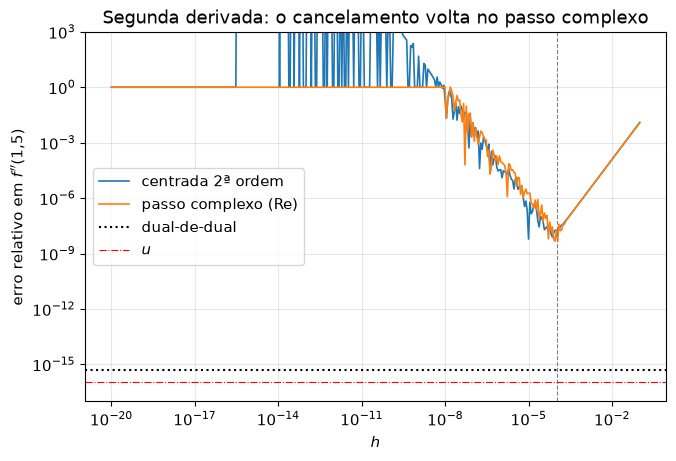

h* teórico ≈ 1.0e-04; melhor erro (complexo) = 4.6e-09; (centrada) = 6.1e-09


In [11]:
hs = torch.logspace(-20, -1, 400)
f0 = f_t(x_t)
seg_c  = (f_t(x_t + hs) - 2*f0 + f_t(x_t - hs)) / hs**2
seg_cs = 2*(f0 - f_t(torch.complex(x_t.expand_as(hs), hs)).real) / hs**2
err = lambda v: (v - D[2]).abs().clamp_min(1e-17) / abs(D[2])

# dual aninhado: f''(x0) exata
xx = Dual(Dual(x0, 1.0), Dual(1.0, 0.0))
d2 = f1(xx).du.du
print(f"dual-de-dual f'' = {d2:.16f}   erro rel. = {abs(d2-D[2])/D[2]:.1e}")

h_cs2 = (48*u*abs(D[0])/abs(D[4]))**0.25

fig, ax = plt.subplots()
ax.loglog(hs, err(seg_c), label="centrada 2ª ordem", lw=1.2)
ax.loglog(hs, err(seg_cs), label="passo complexo (Re)", lw=1.2)
ax.axhline(abs(d2-D[2])/D[2] if d2 != D[2] else u, color="k", ls=":", label="dual-de-dual")
ax.axvline(h_cs2, color="gray", ls="--", lw=0.8)
ax.axhline(u, color="r", ls="-.", lw=0.8, label="$u$")
ax.set_xlabel("$h$"); ax.set_ylabel("erro relativo em $f''(1{,}5)$")
ax.set_title("Segunda derivada: o cancelamento volta no passo complexo")
ax.set_ylim(1e-17, 1e3); ax.legend()
fig.savefig(FIG/"a3_segunda_derivada.pdf", bbox_inches="tight"); plt.show()
print(f"h* teórico ≈ {h_cs2:.1e}; melhor erro (complexo) = {err(seg_cs).min():.1e}; (centrada) = {err(seg_c).min():.1e}")

O passo complexo para $f''$ tem o mesmo "V" das diferenças finitas: **a parte real não tem a proteção contra cancelamento que a parte imaginária tinha**. O truque funciona para $f'$ porque, na parte imaginária, a primeira contribuição *é* a derivada (não há um termo $O(1)$ a subtrair). Para derivadas de ordem $k$ seriam necessárias unidades imaginárias "independentes" (números multicomplexos, Lantoine et al. 2012) ou hiperduais — exatamente o que o dual-de-dual faz, sem nenhum $h$.

## C1. Erro em função de $h$ (log-log)

Fórmulas (todas com $f$ avaliada em `float64` no PyTorch, vetorizado em $h$):

| Método | Aproximação | Erro de truncamento | Arredondamento | $h^\ast$ | Erro mínimo |
|---|---|---|---|---|---|
| progressiva | $\frac{f(x+h)-f(x)}{h}$ | $\frac{h}{2}\lvert f''\rvert$ | $\frac{2u\lvert f\rvert}{h}$ | $2\sqrt{u\lvert f\rvert/\lvert f''\rvert}$ | $\sim u^{1/2}$ |
| centrada | $\frac{f(x+h)-f(x-h)}{2h}$ | $\frac{h^2}{6}\lvert f'''\rvert$ | $\frac{u\lvert f\rvert}{h}$ | $\left(3u\lvert f\rvert/\lvert f'''\rvert\right)^{1/3}$ | $\sim u^{2/3}$ |
| Richardson | $\frac{4D_c(h/2)-D_c(h)}{3}$ | $\frac{h^4}{480}\lvert f^{(5)}\rvert$ | $\frac{3u\lvert f\rvert}{h}$ | $\left(360u\lvert f\rvert/\lvert f^{(5)}\rvert\right)^{1/5}$ | $\sim u^{4/5}$ |
| passo complexo | $\frac{\operatorname{Im}f(x+ih)}{h}$ | $\frac{h^2}{6}\lvert f'''\rvert$ | $\sim u\lvert f'\rvert$ (sem $1/h$) | qualquer $h\le\sqrt{6u\lvert f'\rvert/\lvert f'''\rvert}$ | $\sim u$ |

Para o passo complexo, a linha vertical marca o $h$ **a partir do qual** o truncamento fica abaixo de $u$; qualquer $h$ menor serve (até $10^{-300}$).

progressiva     h* teórico = 1.2e-08   erro mínimo observado = 1.3e-09 em h = 7.8e-09
centrada        h* teórico = 3.0e-06   erro mínimo observado = 8.1e-12 em h = 9.7e-07
Richardson      h* teórico = 6.4e-04   erro mínimo observado = 4.6e-14 em h = 7.5e-04
passo complexo  h* teórico = 6.5e-09   erro mínimo observado = 1.0e-17 em h = 1.0e-20


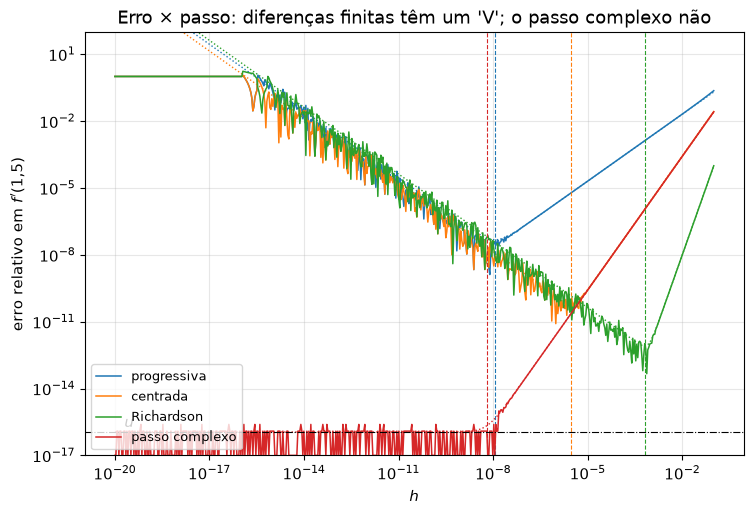


Dual (sem h): 0.0


In [12]:
hs = torch.logspace(-20, -1, 600)
xh = x_t.expand_as(hs)
Dc = lambda h: (f_t(xh + h) - f_t(xh - h)) / (2*h)
aprox = {
    "progressiva":    (f_t(xh + hs) - f_t(xh)) / hs,
    "centrada":       Dc(hs),
    "Richardson":     (4*Dc(hs/2) - Dc(hs)) / 3,
    "passo complexo": f_t(torch.complex(xh, hs)).imag / hs,
}
fa, f2a, f3a, f5a = abs(D[0]), abs(D[2]), abs(D[3]), abs(D[5])
hstar = {
    "progressiva":    2*math.sqrt(u*fa/f2a),
    "centrada":       (3*u*fa/f3a)**(1/3),
    "Richardson":     (360*u*fa/f5a)**(1/5),
    "passo complexo": math.sqrt(6*u*abs(D[1])/f3a),
}
modelo = {   # erro absoluto previsto (truncamento + arredondamento)
    "progressiva":    lambda h: h*f2a/2 + 2*u*fa/h,
    "centrada":       lambda h: h**2*f3a/6 + u*fa/h,
    "Richardson":     lambda h: h**4*f5a/480 + 3*u*fa/h,
    "passo complexo": lambda h: h**2*f3a/6 + u*abs(D[1]),
}
cores = dict(zip(aprox, ["C0", "C1", "C2", "C3"]))

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for nome, v in aprox.items():
    e = ((v - fp_ref).abs() / abs(fp_ref)).clamp_min(1e-17)
    ax.loglog(hs, e, color=cores[nome], lw=1.1, label=nome)
    ax.loglog(hs, modelo[nome](hs)/abs(fp_ref), color=cores[nome], ls=":", lw=1)
    ax.axvline(hstar[nome], color=cores[nome], ls="--", lw=0.8)
    print(f"{nome:15s} h* teórico = {hstar[nome]:.1e}   erro mínimo observado = {e.min():.1e} "
          f"em h = {hs[e.argmin()]:.1e}")
ax.axhline(u, color="k", ls="-.", lw=0.8)
ax.text(2e-20, u*1.6, "$u$", fontsize=11)
ax.set_xlabel("$h$"); ax.set_ylabel("erro relativo em $f'(1{,}5)$")
ax.set_ylim(1e-17, 1e2)
ax.set_title("Erro × passo: diferenças finitas têm um 'V'; o passo complexo não")
ax.legend(loc="lower left", fontsize=9)
fig.savefig(FIG/"c1_erro_vs_h.pdf", bbox_inches="tight"); plt.show()

print("\nDual (sem h):", abs(deriv_dual(f1, x0) - fp_ref)/fp_ref)

**Interpretação.** À direita de cada mínimo domina o truncamento (inclinação $p$ = ordem do método: 1, 2, 4, 2). À esquerda domina o arredondamento (inclinação $-1$, o termo $u/h$), que **só existe porque há uma subtração** $f(x+h)-f(x\pm h)$ de números que concordam em quase todos os dígitos. Aumentar a ordem $p$ empurra o mínimo para baixo ($u^{p/(p+1)}$), mas nunca até $u$. Para $h<u\,|x|$ a soma $x+h$ é arredondada para $x$ e as diferenças finitas devolvem $0$ (erro relativo 1).

O passo complexo tem o mesmo truncamento da centrada, mas a perna esquerda do "V" sumiu: o erro estaciona em $\sim u$ para todo $h \lesssim 10^{-8}$. As linhas pontilhadas são o modelo teórico.

## C2. Gradiente em $\mathbb{R}^{100}$

$$ f(x) = \tfrac12 x^\top A x - b^\top x, \qquad \nabla f(x) = \tfrac12(A + A^\top)x - b .$$

Métodos:
1. diferenças centradas: $2n = 200$ avaliações de $f$;
2. passo complexo: $n = 100$ avaliações complexas;
3. `Dual` vetorizada: **uma** avaliação, com `du` igual à identidade $n\times n$ (as $n$ direções propagadas juntas);
4. (referências) `torch.func.jacfwd` (modo direto do PyTorch) e `torch.autograd` (modo **reverso**).

In [13]:
n = 100
g = torch.Generator().manual_seed(1)
A = torch.randn(n, n, generator=g)            # não simétrica, de propósito
b = torch.randn(n, generator=g)
xg = torch.randn(n, generator=g)
grad_exato = 0.5*(A + A.T) @ xg - b

def fq(x, A=A, b=b):
    # mesma função para tensores reais, complexos e Dual
    return 0.5 * (x @ (A @ x)) - b @ x

Ac, bc = A.to(torch.complex128), b.to(torch.complex128)
fq_c = lambda z: fq(z, Ac, bc)                 # A e b complexos para o passo complexo

def grad_centrada(x):
    gr = torch.empty(n); h = (3*u)**(1/3) * max(1.0, x.abs().max().item())
    for i in range(n):
        e = torch.zeros(n); e[i] = h
        gr[i] = (fq(x + e) - fq(x - e)) / (2*h)
    return gr

def grad_complexo(x, h=1e-30):
    gr = torch.empty(n); xc = x.to(torch.complex128)
    for i in range(n):
        e = torch.zeros(n, dtype=torch.complex128); e[i] = 1j*h
        gr[i] = fq_c(xc + e).imag / h
    return gr

def grad_dual(x):
    # semente: du = I (linha i = direção e_i); uma única avaliação
    return fq(Dual(x, torch.eye(n))).du

def grad_jacfwd(x):
    return torch.func.jacfwd(fq)(x)

def grad_reverso(x):
    x = x.clone().requires_grad_(True)
    return torch.autograd.grad(fq(x), x)[0]

def cronometra(fun, rep=7):
    fun(xg)                                    # aquecimento
    ts = []
    for _ in range(rep):
        t = time.perf_counter(); r = fun(xg); ts.append(time.perf_counter() - t)
    return r, float(np.median(ts))

metodos = {"centradas (200 aval.)": grad_centrada, "passo complexo (100 aval.)": grad_complexo,
           "Dual vetorizada (1 aval., n direções)": grad_dual, "torch.func.jacfwd": grad_jacfwd,
           "torch.autograd (reverso)": grad_reverso}
_, t_f = cronometra(fq, rep=50)
print(f"tempo de 1 avaliação de f: {t_f*1e6:.1f} µs\n")
print(f"{'método':40s} {'erro rel. (norma ∞)':>20s} {'tempo':>12s} {'tempo/t_f':>10s}")
resultados_c2 = {}
for nome, fun in metodos.items():
    gr, t = cronometra(fun)
    e = ((gr - grad_exato).abs().max() / grad_exato.abs().max()).item()
    resultados_c2[nome] = (e, t)
    print(f"{nome:40s} {e:20.1e} {t*1e3:10.2f} ms {t/t_f:10.0f}")

tempo de 1 avaliação de f: 8.3 µs

método                                    erro rel. (norma ∞)        tempo  tempo/t_f
centradas (200 aval.)                                 3.8e-11       3.44 ms        417
passo complexo (100 aval.)                            3.1e-16       3.78 ms        457
Dual vetorizada (1 aval., n direções)                 2.1e-16       0.12 ms         15


torch.func.jacfwd                                     2.1e-16       1.19 ms        144
torch.autograd (reverso)                              4.2e-16       0.10 ms         12


Observações:

* O erro das centradas é $\sim u^{2/3}\approx 10^{-11}$; passo complexo, `Dual` e as AD do PyTorch ficam em $\sim u$. (A referência $\tfrac12(A+A^\top)x-b$ também é calculada em ponto flutuante, então "erro" abaixo de $\sim 10^{-15}$ é indistinguível.) Como $f$ é quadrática, a centrada nem tem erro de truncamento aqui ($f'''=0$): o erro observado é **só** cancelamento.
* Os tempos absolutos em $n=100$ são dominados pelo laço em Python. O que importa é como o custo **escala** com $n$ — próximo experimento.

### Escalonamento: modo direto $O(n)$ × modo reverso $O(1)$

Todo método de modo direto (diferenças finitas, passo complexo, duais) calcula **uma derivada direcional** $\nabla f\cdot v$ por avaliação; para o gradiente completo são precisas $n$ direções, então
$$\text{custo}(\nabla f) \approx n\cdot\text{custo}(f).$$
A versão vetorizada do `Dual` faz uma única "passada", mas cada número carrega $n$ derivadas: `A @ du` custa $n^3$ em vez de $n^2$ — o mesmo fator $n$, só que sem o laço em Python.

O modo reverso propaga **adjuntos** $\bar v_i = \partial f/\partial v_i$ da saída para as entradas: uma passada para frente (gravando a "fita") e uma para trás dão o gradiente inteiro, com
$$\text{custo}(\nabla f) \le c\cdot\text{custo}(f), \quad c\approx 3\text{–}5$$
independentemente de $n$ (o "cheap gradient principle", Baydin et al. 2018, §3.2). O preço é memória proporcional ao número de operações gravadas.

n=   10  t_f=     7.3 µs  t_f(complexa)=     8.3 µs  passo:     19.7  Dual:      9.5  torch.autograd:      8.6
n=   30  t_f=     7.1 µs  t_f(complexa)=     9.6 µs  passo:     49.8  Dual:      9.8  torch.autograd:      8.5
n=  100  t_f=     8.2 µs  t_f(complexa)=    19.9 µs  passo:    147.3  Dual:     12.8  torch.autograd:      7.8


n=  300  t_f=    15.0 µs  t_f(complexa)=   111.7 µs  passo:    382.5  Dual:     68.5  torch.autograd:      5.4


n= 1000  t_f=   290.9 µs  t_f(complexa)=  1250.9 µs  passo:   1175.1  Dual:    114.5  torch.autograd:      3.1


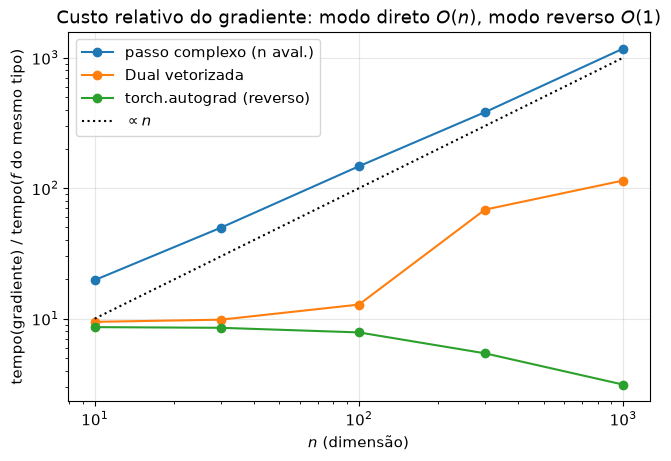

In [14]:
ns = [10, 30, 100, 300, 1000]
razoes = {"passo complexo (n aval.)": [], "Dual vetorizada": [], "torch.autograd (reverso)": []}
for m in ns:
    gm = torch.Generator().manual_seed(2)
    Am, bm, xm = torch.randn(m, m, generator=gm), torch.randn(m, generator=gm), torch.randn(m, generator=gm)
    Amc, bmc = Am.to(torch.complex128), bm.to(torch.complex128)
    fm = lambda x: 0.5*(x @ (Am @ x)) - bm @ x
    fmc = lambda z: 0.5*(z @ (Amc @ z)) - bmc @ z
    def gc():
        xc = xm.to(torch.complex128); E = 1e-30j*torch.eye(m, dtype=torch.complex128)
        return torch.stack([fmc(xc + E[i]).imag for i in range(m)]) / 1e-30
    def gd():
        return fm(Dual(xm, torch.eye(m))).du
    def gr():
        x = xm.clone().requires_grad_(True); return torch.autograd.grad(fm(x), x)[0]
    def mede(fun, rep=9):
        fun(); ts = []
        for _ in range(rep):
            t = time.perf_counter(); fun(); ts.append(time.perf_counter() - t)
        return min(ts)                          # o mínimo é a medida menos ruidosa
    tf  = mede(lambda: fm(xm), rep=50)
    xmc = xm.to(torch.complex128)
    tfc = mede(lambda: fmc(xmc), rep=50)        # custo de UMA avaliação complexa
    for nome, fun, t0 in zip(razoes, [gc, gd, gr], [tfc, tf, tf]):
        razoes[nome].append(mede(fun) / t0)
    print(f"n={m:5d}  t_f={tf*1e6:8.1f} µs  t_f(complexa)={tfc*1e6:8.1f} µs  "
          + "  ".join(f"{k.split()[0]}: {v[-1]:8.1f}" for k, v in razoes.items()))

fig, ax = plt.subplots()
for nome, r in razoes.items():
    ax.loglog(ns, r, "o-", label=nome)
ax.loglog(ns, [m for m in ns], "k:", label="$\\propto n$")
ax.set_xlabel("$n$ (dimensão)"); ax.set_ylabel("tempo(gradiente) / tempo($f$ do mesmo tipo)")
ax.set_title("Custo relativo do gradiente: modo direto $O(n)$, modo reverso $O(1)$")
ax.legend()
fig.savefig(FIG/"c2_escalonamento.pdf", bbox_inches="tight"); plt.show()

Leitura: para $n$ pequeno, o custo fixo de cada chamada (Python, despacho do PyTorch) domina e as razões ficam parecidas. À medida que $n$ cresce, o passo complexo segue a reta $\propto n$ (são $n$ avaliações), enquanto o modo reverso fica limitado por uma constante pequena. A `Dual` vetorizada também faz $O(n)$ vezes mais operações aritméticas que $f$ (o produto `A @ du` é matriz × matriz), mas cresce mais devagar no relógio porque matriz × matriz (BLAS-3) aproveita muito melhor o processador que matriz × vetor (BLAS-2): o custo **assintótico** em operações é o mesmo $O(n)$, a eficiência do hardware é que difere. Os números exatos variam de máquina para máquina.

## C3. Comparação com `jax.grad` (opcional)

In [15]:
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

f1_jax = lambda x: jnp.exp(x) / (jnp.cos(x)**3 + jnp.sin(x)**3)
gj = float(jax.grad(f1_jax)(1.5))
print(f"jax.grad f1(1.5)       = {gj:.16f}   erro rel. {abs(gj-fp_ref)/fp_ref:.1e}")
print(f"deriv_dual f1(1.5)     = {deriv_dual(f1, 1.5):.16f}")
print(f"deriv_complexa f1(1.5) = {deriv_complexa(f1, 1.5):.16f}")

Aj, bj, xj = map(lambda t: jnp.array(t.numpy()), (A, b, xg))
gq = jax.grad(lambda x: 0.5*(x @ (Aj @ x)) - bj @ x)(xj)
print(f"\nC2 com jax.grad: erro rel. = {float(jnp.abs(gq - grad_exato.numpy()).max() / jnp.abs(grad_exato.numpy()).max()):.1e}")

print("\nDerivada de |x| em x = 0:")
print("  jax.grad(jnp.abs)(0.)        =", float(jax.grad(jnp.abs)(0.0)))
t0 = torch.tensor(0.0, requires_grad=True); torch.abs(t0).backward()
print("  torch.autograd (torch.abs)    =", t0.grad.item())
print("  nosso Dual (sign(0)=+1)       =", deriv_dual(abs, 0.0))
print("  passo complexo com abs_cs     =", deriv_complexa(abs_cs, 0.0))
print("  passo complexo com np.abs     =", deriv_complexa(np.abs, 0.0))
print("  jax.grad(sqrt(x²))(0.)        =", float(jax.grad(lambda x: jnp.sqrt(x*x))(0.0)))
relu = lambda x: jnp.maximum(x, 0.0)
print("  jax.grad(relu)(0.)            =", float(jax.grad(relu)(0.0)))

jax.grad f1(1.5)       = 3.6220337007163259   erro rel. 0.0e+00
deriv_dual f1(1.5)     = 3.6220337007163259
deriv_complexa f1(1.5) = 3.6220337007163255



C2 com jax.grad: erro rel. = 4.2e-16

Derivada de |x| em x = 0:
  jax.grad(jnp.abs)(0.)        = 1.0
  torch.autograd (torch.abs)    = 0.0
  nosso Dual (sign(0)=+1)       = 1.0
  passo complexo com abs_cs     = 1.0
  passo complexo com np.abs     = 0.0
  jax.grad(sqrt(x²))(0.)        = nan


  jax.grad(relu)(0.)            = 0.5


**Discussão.** $|x|$ não tem derivada em $0$; o subdiferencial é $[-1, 1]$. Cada ferramenta escolhe uma convenção **silenciosamente**:

* `jax.grad(jnp.abs)(0.) = 1` — o JAX deriva $|x|$ por meio de uma seleção do tipo `x >= 0 ? x : -x`, que em $0$ cai no ramo positivo: derivada lateral à direita (igual ao nosso `Dual` e ao `abs_cs`);
* `torch.abs` usa $\operatorname{sign}(0)=0$, o subgradiente de norma mínima;
* `np.abs` no passo complexo devolve $0$ em *qualquer* ponto (o módulo complexo apaga a parte imaginária);
* $\sqrt{x^2}$, matematicamente igual a $|x|$, dá `nan` em AD: a derivada depende do **programa**, não da função matemática;
* `jax.grad` de $\max(x,0)$ (ReLU) em $0$ dá $0{,}5$: o JAX reparte o gradiente igualmente entre os argumentos empatados de `maximum`. Ainda outra convenção.

Moral: AD calcula a derivada exata **do programa avaliado no ramo percorrido**. Em pontos de não-diferenciabilidade o resultado é uma convenção (às vezes um subgradiente útil, às vezes `nan`), nunca um aviso.

## Resumo

| | Diferenças finitas | Passo complexo | AD (duais / modo direto) | AD modo reverso |
|---|---|---|---|---|
| Melhor erro | $u^{p/(p+1)}$ | $\sim u$ | $\sim u$ | $\sim u$ |
| Escolha de $h$ | crítica | irrelevante ($h\ll\sqrt u$) | não há | não há |
| Exige de $f$ | só avaliar (caixa-preta) | analítica + código complex-safe | código com operações sobrecarregáveis | idem + fita |
| Atravessa código compilado | sim | se aceitar complexos | não (precisa de regra própria) | não (precisa de regra própria) |
| Custo do gradiente em $\mathbb{R}^n$ | $n$ ou $2n$ avaliações | $n$ avaliações complexas ($\approx 2$–$4\times$ mais caras) | $n$ direções | $O(1)$ avaliações, memória $O(\#\text{ops})$ |
| 2ª derivada | cancelamento | cancelamento volta | exata (dual aninhado) | exata (aninhando) |